# DWD-Wetterdaten Berlin ab 2020

Dieses Notebook lädt die vorbereitete CSV-Datei mit täglichen DWD-Beobachtungen der Station **Berlin-Dahlem (FU), Stations-ID 00403**. Die Quelle ist das [DWD Climate Data Center: tägliche Klimawerte](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/).

Die Datei enthält eine Zeile pro Kalendertag vom 2020-01-01 bis zum letzten verfügbaren Stationsdatum, derzeit 2026-11-01. Für 2026 sind die Daten somit noch nicht vollständig. Fehlende Messwerte und Tage sind als leere CSV-Felder gespeichert; es wurden keine Werte geschätzt.

Berlin-Dahlem wurde gewählt, weil dort alle fünf gewünschten Messgrößen weitgehend vorliegen. Zum Vergleich: Bei Berlin-Tempelhof (00433) gab es im selben Zeitraum Sonnenstunden nur an 984 von 2.497 Tagen.

## Spalten und Verfügbarkeit

| CSV-Spalte | DWD-Kürzel | Einheit | Vorhanden |
|---|---|---|---:|
| `temp_min_C` | `TNK` | °C | 2.481 / 2.497 Tage |
| `temp_max_C` | `TXK` | °C | 2.481 / 2.497 Tage |
| `temp_durchschnitt_C` | `TMK` | °C | 2.481 / 2.497 Tage |
| `niederschlagsmenge_mm` | `RSK` | mm | 2.482 / 2.497 Tage |
| `sonnenstunden_h` | `SDK` | Stunden | 2.481 / 2.497 Tage |

Die Werte stammen aus den DWD-Dateien für historische und aktuelle Tagesdaten. Überschneidungen wurden anhand des Datums zusammengeführt; bei Überschneidungen gilt der aktuelle Datensatz.

In [1]:
import csv
from pathlib import Path

csv_pfad = Path("wetterdaten_berlin_2020_bis_heute.csv")
spalten = [
    "temp_min_C",
    "temp_max_C",
    "temp_durchschnitt_C",
    "niederschlagsmenge_mm",
    "sonnenstunden_h",
]

with csv_pfad.open(encoding="utf-8-sig", newline="") as datei:
    messwerte = list(csv.DictReader(datei))

print(f"Datei: {csv_pfad.resolve()}")
print(f"Tageszeilen: {len(messwerte)}")
print(f"Zeitraum: {messwerte[0]['datum']} bis {messwerte[-1]['datum']}")
print("Vorhandene Werte je Messgröße:")
for spalte in spalten:
    vorhanden = sum(bool(zeile[spalte]) for zeile in messwerte)
    print(f"{spalte}: {vorhanden}/{len(messwerte)}")

print("\nErste drei Tageszeilen:")
for zeile in messwerte[:3]:
    print(zeile)

Datei: /workspaces/021126_Softwareentwicklung/wetterdaten_berlin_2020_bis_heute.csv
Tageszeilen: 2497
Zeitraum: 2020-01-01 bis 2026-11-01
Vorhandene Werte je Messgröße:
temp_min_C: 2481/2497
temp_max_C: 2481/2497
temp_durchschnitt_C: 2481/2497
niederschlagsmenge_mm: 2482/2497
sonnenstunden_h: 2481/2497

Erste drei Tageszeilen:
{'datum': '2020-01-01', 'temp_min_C': '-2.8', 'temp_max_C': '5.0', 'temp_durchschnitt_C': '1.8', 'niederschlagsmenge_mm': '0.0', 'sonnenstunden_h': '2.9'}
{'datum': '2020-01-02', 'temp_min_C': '-4.1', 'temp_max_C': '6.2', 'temp_durchschnitt_C': '-0.3', 'niederschlagsmenge_mm': '0.0', 'sonnenstunden_h': '7.5'}
{'datum': '2020-01-03', 'temp_min_C': '0.8', 'temp_max_C': '6.9', 'temp_durchschnitt_C': '4.3', 'niederschlagsmenge_mm': '4.4', 'sonnenstunden_h': '0.0'}


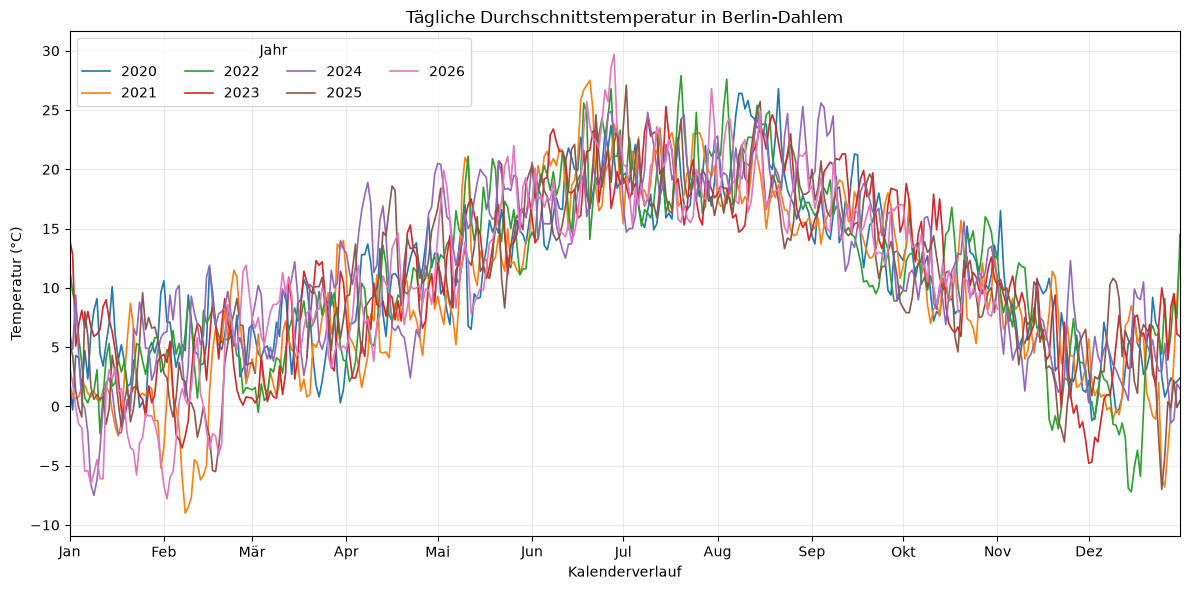

In [2]:
from collections import defaultdict
from datetime import datetime
import math

import matplotlib.dates as mdates
import matplotlib.pyplot as plt

temperaturen_pro_jahr = defaultdict(list)
for zeile in messwerte:
    datum = datetime.strptime(zeile["datum"], "%Y-%m-%d")
    kalenderdatum = datetime.strptime(f"2000-{datum:%m-%d}", "%Y-%m-%d")
    temperatur = float(zeile["temp_durchschnitt_C"]) if zeile["temp_durchschnitt_C"] else math.nan
    temperaturen_pro_jahr[datum.year].append((kalenderdatum, temperatur))

fig, ax = plt.subplots(figsize=(12, 6))
for jahr, werte in sorted(temperaturen_pro_jahr.items()):
    ax.plot(
        [datum for datum, _ in werte],
        [temperatur for _, temperatur in werte],
        label=str(jahr),
        linewidth=1.2,
    )

monatserste = [datetime(2000, monat, 1) for monat in range(1, 13)]
monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
ax.set_xticks(monatserste, monatsnamen)
ax.set_xlim(datetime(2000, 1, 1), datetime(2000, 12, 31))
ax.set_title("Tägliche Durchschnittstemperatur in Berlin-Dahlem")
ax.set_xlabel("Kalenderverlauf")
ax.set_ylabel("Temperatur (°C)")
ax.grid(True, alpha=0.25)
ax.legend(title="Jahr", ncols=4)
fig.tight_layout()
plt.show()

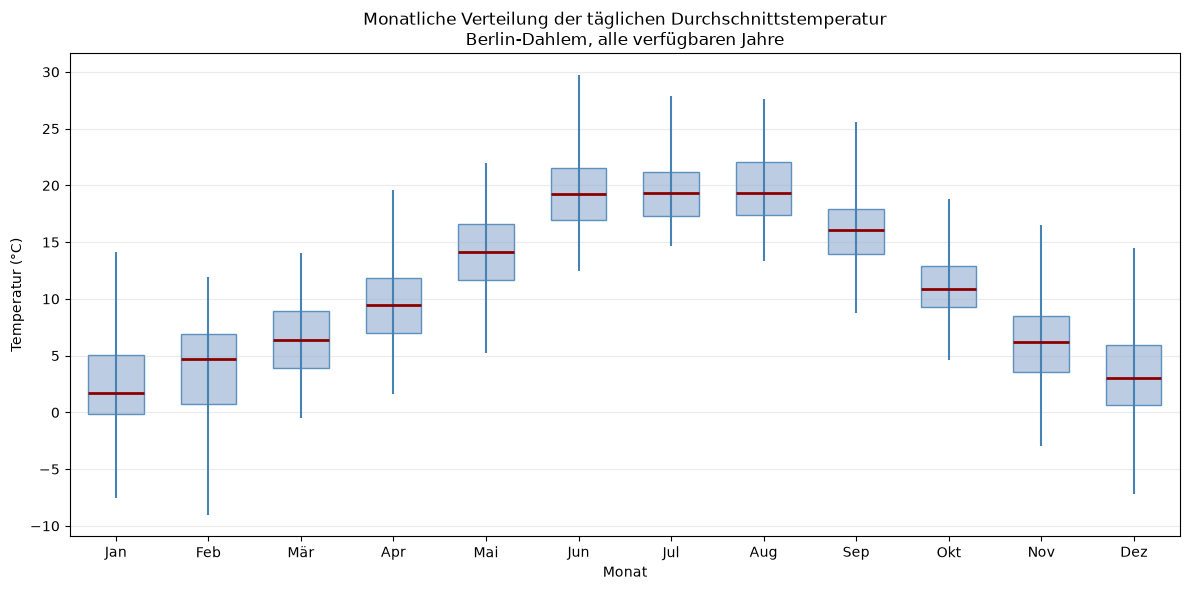

Winter (Dez–Feb): IQR 5.5 °C, Gesamtspanne -9.0 bis 14.5 °C
Sommer (Jun–Aug): IQR 4.3 °C, Gesamtspanne 12.5 bis 29.7 °C


In [3]:
temperaturen_pro_monat = {monat: [] for monat in range(1, 13)}

for zeile in messwerte:
    if zeile["temp_durchschnitt_C"]:
        monat = int(zeile["datum"][5:7])
        temperaturen_pro_monat[monat].append(float(zeile["temp_durchschnitt_C"]))


def quantil(daten, anteil):
    sortiert = sorted(daten)
    position = (len(sortiert) - 1) * anteil
    unten = int(position)
    oben = min(unten + 1, len(sortiert) - 1)
    gewicht = position - unten
    return sortiert[unten] * (1 - gewicht) + sortiert[oben] * gewicht


monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun",
               "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]

fig, ax = plt.subplots(figsize=(12, 6))

for monat, daten in temperaturen_pro_monat.items():
    if not daten:
        continue

    minimum = min(daten)
    maximum = max(daten)
    q1 = quantil(daten, 0.25)
    median = quantil(daten, 0.50)
    q3 = quantil(daten, 0.75)

    # Docht: Minimum bis Maximum; Körper: erstes bis drittes Quartil
    ax.vlines(monat, minimum, maximum, color="steelblue", linewidth=1.5)
    ax.add_patch(
        plt.Rectangle(
            (monat - 0.3, q1),
            0.6,
            q3 - q1,
            facecolor="lightsteelblue",
            edgecolor="steelblue",
            alpha=0.85,
        )
    )
    ax.hlines(median, monat - 0.3, monat + 0.3, color="darkred", linewidth=2)

ax.set_xticks(range(1, 13), monatsnamen)
ax.set_xlim(0.5, 12.5)
ax.set_title("Monatliche Verteilung der täglichen Durchschnittstemperatur\nBerlin-Dahlem, alle verfügbaren Jahre")
ax.set_xlabel("Monat")
ax.set_ylabel("Temperatur (°C)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

winterwerte = [
    wert
    for monat in (12, 1, 2)
    for wert in temperaturen_pro_monat[monat]
]
sommerwerte = [
    wert
    for monat in (6, 7, 8)
    for wert in temperaturen_pro_monat[monat]
]

print(
    f"Winter (Dez–Feb): IQR {quantil(winterwerte, 0.75) - quantil(winterwerte, 0.25):.1f} °C, "
    f"Gesamtspanne {min(winterwerte):.1f} bis {max(winterwerte):.1f} °C"
)
print(
    f"Sommer (Jun–Aug): IQR {quantil(sommerwerte, 0.75) - quantil(sommerwerte, 0.25):.1f} °C, "
    f"Gesamtspanne {min(sommerwerte):.1f} bis {max(sommerwerte):.1f} °C"
)

# Datenanalyse

## Typischer Analyseworkflow

1. **Datenquelle und Analyseumfang definieren**  
    DWD-Tagesdaten der Station Berlin-Dahlem und den Analysezeitraum festlegen.

2. **Datenakquise und Datenimport**  
    Die CSV-Datei einlesen und Datenstruktur, Zeitraum sowie Anzahl der Beobachtungen prüfen.

3. **Datenprofiling und Qualitätsprüfung**  
    Verfügbarkeit der Messwerte je Variable untersuchen und fehlende Werte dokumentieren. Fehlende Werte werden nicht imputiert.

4. **Datenaufbereitung (Preprocessing)**  
    Datumsangaben und Messwerte in geeignete Datentypen überführen und die Daten für zeitliche Aggregationen gruppieren.

5. **Explorative Datenanalyse (EDA)**  
    Temperaturverläufe visualisieren, um saisonale Muster und Unterschiede zwischen Jahren zu identifizieren.

6. **Deskriptive Statistik und Verteilungsanalyse**  
    Monatliche Minima, Quartile, Mediane und Maxima der täglichen Durchschnittstemperatur berechnen und visualisieren.

7. **Saisonaler Vergleich**  
    Winter- und Sommerwerte anhand geeigneter Kennzahlen, etwa Interquartilsabstand und Gesamtspanne, vergleichen.

8. **Ergebnisse interpretieren und Einschränkungen dokumentieren**  
    Befunde im Kontext der Datenvollständigkeit und des Analysezeitraums einordnen. Das aktuelle Jahr ist unvollständig und daher nur eingeschränkt vergleichbar.

# Datenprognose mit KI

## 1. Aufgabe und Merkmale

Wir formulieren eine **Ein-Tages-Prognose**: Für einen Zieltage sollen die fünf davor gemessenen Tagesdurchschnittstemperaturen und der Kalendertag die Durchschnittstemperatur des Zieltags vorhersagen. Ein Lernbeispiel hat somit sechs Eingabewerte (`X`) und einen Zielwert (`y`).

Beispiel: Die Temperaturen von 1. bis 5. Januar sowie der Kalendertag 6 bilden ein Beispiel; Ziel ist die gemessene Temperatur vom 6. Januar. Es werden nur Beispiele angelegt, bei denen alle sechs Temperaturwerte vorhanden sind. Fehlende Messungen werden also nicht künstlich ersetzt.

Der Kalendertag wird auf 1 bis 365 vereinheitlicht. Im Schaltjahr wird der 29. Februar dem Tag 59 zugeordnet und die Tage danach werden um eins verschoben. So entspricht etwa der 1. März in jedem Jahr demselben Saisonmerkmal.

In [1]:
import csv
from calendar import isleap
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np

csv_pfad = Path("wetterdaten_berlin_2020_bis_heute.csv")
with csv_pfad.open(encoding="utf-8-sig", newline="") as datei:
    csv_zeilen = list(csv.DictReader(datei))

temperatur_nach_datum = {
    datetime.strptime(zeile["datum"], "%Y-%m-%d").date(): float(zeile["temp_durchschnitt_C"])
    for zeile in csv_zeilen
    if zeile["temp_durchschnitt_C"]
}


def tag_im_jahr_365(datum):
    """Ordnet alle Daten einem Kalender mit genau 365 Tagen zu."""
    tag = datum.timetuple().tm_yday
    if isleap(datum.year) and datum.month == 2 and datum.day == 29:
        return 59
    if isleap(datum.year) and datum.month > 2:
        return tag - 1
    return tag


merkmalnamen = [
    "temp_vor_5_tagen_C",
    "temp_vor_4_tagen_C",
    "temp_vor_3_tagen_C",
    "temp_vor_2_tagen_C",
    "temp_vortag_C",
    "tag_im_jahr",
]
merkmalzeilen = []
zielwerte = []
prognosedaten = []

for ziel_datum in sorted(temperatur_nach_datum):
    vergangene_tage = [ziel_datum - timedelta(days=abstand) for abstand in range(5, 0, -1)]
    if any(datum not in temperatur_nach_datum for datum in vergangene_tage):
        continue

    merkmale = [temperatur_nach_datum[datum] for datum in vergangene_tage]
    merkmale.append(tag_im_jahr_365(ziel_datum))
    merkmalzeilen.append(merkmale)
    zielwerte.append(temperatur_nach_datum[ziel_datum])
    prognosedaten.append(ziel_datum)

X = np.asarray(merkmalzeilen, dtype=float)
y = np.asarray(zielwerte, dtype=float)
print(f"Trainingsbeispiele insgesamt: {len(y)}")
print(f"Merkmalsmatrix X: {X.shape} (Beispiele, Merkmale)")
print(f"Zielvektor y: {y.shape}")
print(f"Erstes Beispiel ({prognosedaten[0]}):")
print(dict(zip(merkmalnamen, X[0])))
print(f"Ziel: {y[0]:.1f} °C")

Trainingsbeispiele insgesamt: 2471
Merkmalsmatrix X: (2471, 6) (Beispiele, Merkmale)
Zielvektor y: (2471,)
Erstes Beispiel (2020-01-06):
{'temp_vor_5_tagen_C': np.float64(1.8), 'temp_vor_4_tagen_C': np.float64(-0.3), 'temp_vor_3_tagen_C': np.float64(4.3), 'temp_vor_2_tagen_C': np.float64(4.1), 'temp_vortag_C': np.float64(1.4), 'tag_im_jahr': np.float64(6.0)}
Ziel: 4.7 °C


## 2. Chronologischer Train/Test-Schnitt

Wir trainieren auf Zieltagen aus **2020 bis 2024** und testen auf dem danach liegenden, im Training ungesehenen Jahr **2025**. Ein zufälliger Split wäre für Zeitreihen ungeeignet: Er könnte frühere und spätere Tage mischen und dadurch eine unrealistisch gute Bewertung erzeugen.

Die fünf Temperaturmerkmale eines Testtags sind dessen tatsächlich gemessene Vortage. Das entspricht einer rollierenden Ein-Tages-Prognose, bei der die Beobachtungen des Vortags verfügbar sind. Die unvollständigen Daten von 2026 bleiben für diesen Genauigkeitstest außen vor.

In [2]:
testjahr = 2025
train_maske = np.array([datum.year < testjahr for datum in prognosedaten])
test_maske = np.array([datum.year == testjahr for datum in prognosedaten])

X_train, y_train = X[train_maske], y[train_maske]
X_test, y_test = X[test_maske], y[test_maske]
test_daten = [datum for datum, ist_test in zip(prognosedaten, test_maske) if ist_test]

assert len(X_train) > 0 and len(X_test) > 0
print(f"Trainingsbeispiele 2020–2024: {len(X_train)}")
print(f"Testbeispiele 2025: {len(X_test)}")
print(f"Testzeitraum: {test_daten[0]} bis {test_daten[-1]}")

Trainingsbeispiele 2020–2024: 1822
Testbeispiele 2025: 344
Testzeitraum: 2025-01-01 bis 2025-12-31


## 3. Einfaches KI-Modell trainieren

Ein **Random Forest** besteht aus vielen Entscheidungsbäumen. Jeder Baum lernt Regeln aus Trainingsbeispielen; für eine Prognose mittelt das Modell die Baum-Ergebnisse. Es kann nichtlineare Zusammenhänge zwischen Jahreszeit, den fünf Vortagen und der Temperatur abbilden.

Wir verwenden 300 Bäume und mindestens drei Beispiele pro Blatt. Das begrenzt sehr kleinteilige Regeln etwas. `random_state` sorgt dafür, dass der Lauf reproduzierbar ist. Die Baum-Methode benötigt keine Skalierung der Eingabewerte.

In [3]:
from sklearn.ensemble import RandomForestRegressor

modell = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
)
modell.fit(X_train, y_train)
prognose_test = modell.predict(X_test)

# Referenz: Der nächste Tag soll genauso warm sein wie der letzte Vortag.
prognose_referenz = X_test[:, 4]


def zeige_fehler(name, wirklich, vorhergesagt):
    fehler = wirklich - vorhergesagt
    mae = np.mean(np.abs(fehler))
    rmse = np.sqrt(np.mean(fehler ** 2))
    r_quadrat = 1 - np.sum(fehler ** 2) / np.sum((wirklich - np.mean(wirklich)) ** 2)
    print(f"{name}: MAE {mae:.2f} °C | RMSE {rmse:.2f} °C | R² {r_quadrat:.3f}")


zeige_fehler("Random Forest", y_test, prognose_test)
zeige_fehler("Referenz (Vortag übernehmen)", y_test, prognose_referenz)

Random Forest: MAE 1.67 °C | RMSE 2.13 °C | R² 0.911
Referenz (Vortag übernehmen): MAE 1.76 °C | RMSE 2.26 °C | R² 0.900


## 4. Genauigkeit verstehen

- **MAE** ist der durchschnittliche absolute Fehler in Grad Celsius. 1,67 °C bedeutet: Die Prognose lag 2025 im Mittel etwa 1,67 °C neben dem Messwert. Kleiner ist besser.
- **RMSE** misst ebenfalls den Fehler in °C, gewichtet aber größere Abweichungen stärker. Auch hier ist kleiner besser.
- **R²** vergleicht das Modell mit einer konstanten Vorhersage des Testmittelwerts. Ein Wert näher an 1 beschreibt hier eine bessere Anpassung.

Die Referenz „Vortag übernehmen“ ist ein einfacher Vergleich: Sie sagt für morgen dieselbe Temperatur wie für gestern voraus. Der Random Forest ist im Test etwas besser, sein Vorteil ist aber nicht groß. Die folgende Grafik zeigt, wann sich Modell und Messung unterscheiden.

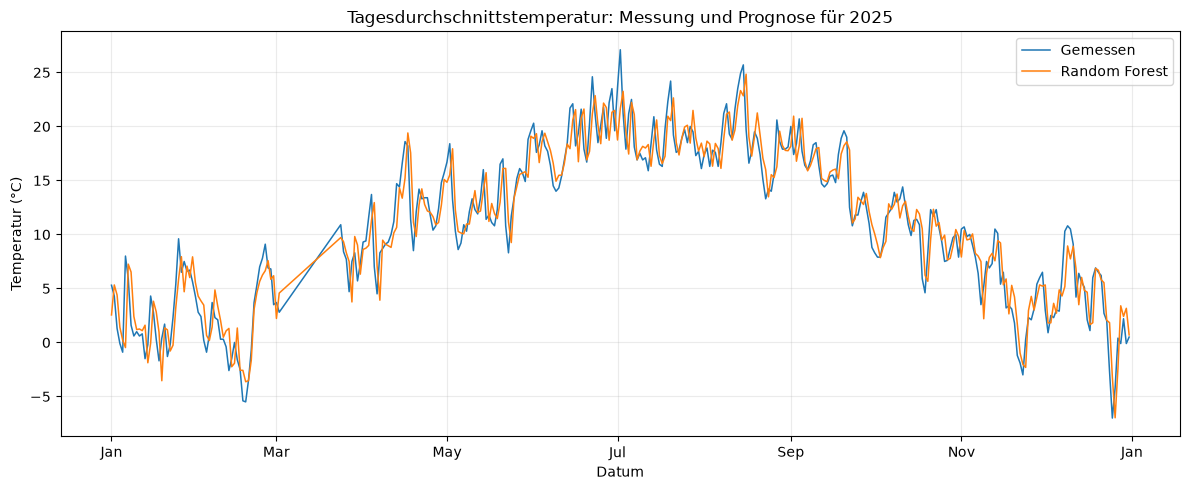

In [4]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

test_datumswerte = [datetime.combine(datum, datetime.min.time()) for datum in test_daten]
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test_datumswerte, y_test, label="Gemessen", linewidth=1.1)
ax.plot(test_datumswerte, prognose_test, label="Random Forest", linewidth=1.1)
ax.set_title("Tagesdurchschnittstemperatur: Messung und Prognose für 2025")
ax.set_ylabel("Temperatur (°C)")
ax.set_xlabel("Datum")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## 5. Nächsten Tag prognostizieren

Der Test aus 2025 bewertet, wie gut das Verfahren auf einem späteren, ungesehenen Jahr funktioniert. Für eine aktuelle Prognose trainieren wir danach ein neues Modell mit **allen** verfügbaren Beispielen. Als Eingabe dienen die letzten fünf tatsächlich gemessenen Tagesmittel und der Kalendertag nach der letzten Beobachtung. Die Prognose ist ein einfacher Modellwert, keine amtliche Wettervorhersage.

In [5]:
letzter_messwert_tag = max(temperatur_nach_datum)
prognosetag = letzter_messwert_tag + timedelta(days=1)
letzte_fuenf_tage = [prognosetag - timedelta(days=abstand) for abstand in range(5, 0, -1)]

if any(datum not in temperatur_nach_datum for datum in letzte_fuenf_tage):
    raise ValueError("Für die Prognose fehlen Messwerte an einem der letzten fünf Tage.")

prognose_merkmale = np.asarray([[
    *[temperatur_nach_datum[datum] for datum in letzte_fuenf_tage],
    tag_im_jahr_365(prognosetag),
]])

modell_aktuell = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
)
modell_aktuell.fit(X, y)
temperatur_prognose = modell_aktuell.predict(prognose_merkmale)[0]

print(f"Letzter Messwert: {letzter_messwert_tag}")
print(f"Prognosetag: {prognosetag}")
print("Verwendete Temperaturen der fünf Vortage:")
for datum in letzte_fuenf_tage:
    print(f"{datum}: {temperatur_nach_datum[datum]:.1f} °C")
print(f"Prognostizierte Tagesdurchschnittstemperatur: {temperatur_prognose:.1f} °C")

Letzter Messwert: 2026-11-01
Prognosetag: 2026-11-02
Verwendete Temperaturen der fünf Vortage:
2026-10-28: 8.8 °C
2026-10-29: 7.8 °C
2026-10-30: 7.6 °C
2026-10-31: 9.0 °C
2026-11-01: 8.2 °C
Prognostizierte Tagesdurchschnittstemperatur: 8.9 °C
